In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [45]:
import os
import numpy as no
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import Sequential
from keras.layers import Dense,Flatten,Conv2D,MaxPooling2D,Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

import warnings
warnings.filterwarnings('ignore')


In [46]:
train_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/train'
test_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/test'
val_path = '/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images/validation'


In [47]:
len(os.listdir(train_path + '/' + 'Bean'))

1000

In [48]:
def count_image(folder_path):
    images= {}
    classes = os.listdir(folder_path)
    
    for class_name in classes:
        folder_image_path = folder_path + '/' + class_name
        image_count = len(os.listdir(folder_image_path))
        images[class_name] = image_count
        
    return images
        
        

In [49]:
train_counts = count_image(train_path)

test_counts = count_image(test_path)

validation_counts = count_image(val_path)

print("Train Counts:")
print(train_counts)

print("\nTest Counts:")
print(test_counts)

print("\nValidation Counts:")
print(validation_counts)

Train Counts:
{'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}

Test Counts:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}

Validation Counts:
{'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [50]:
train_df = pd.DataFrame(list(train_counts.items()),
                       columns = ["Vegetable", "Train Count"])

test_df = pd.DataFrame(
    list(test_counts.items()),
    columns=["Vegetable", "Test Count"]
)

validation_df = pd.DataFrame(
    list(validation_counts.items()),
    columns=["Vegetable", "Validation Count"]
)

In [51]:
summary_df = train_df.merge(test_df,on = "Vegetable")

summary_df = summary_df.merge(validation_df,on = "Vegetable" )
summary_df = summary_df.sort_values("Vegetable")

summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


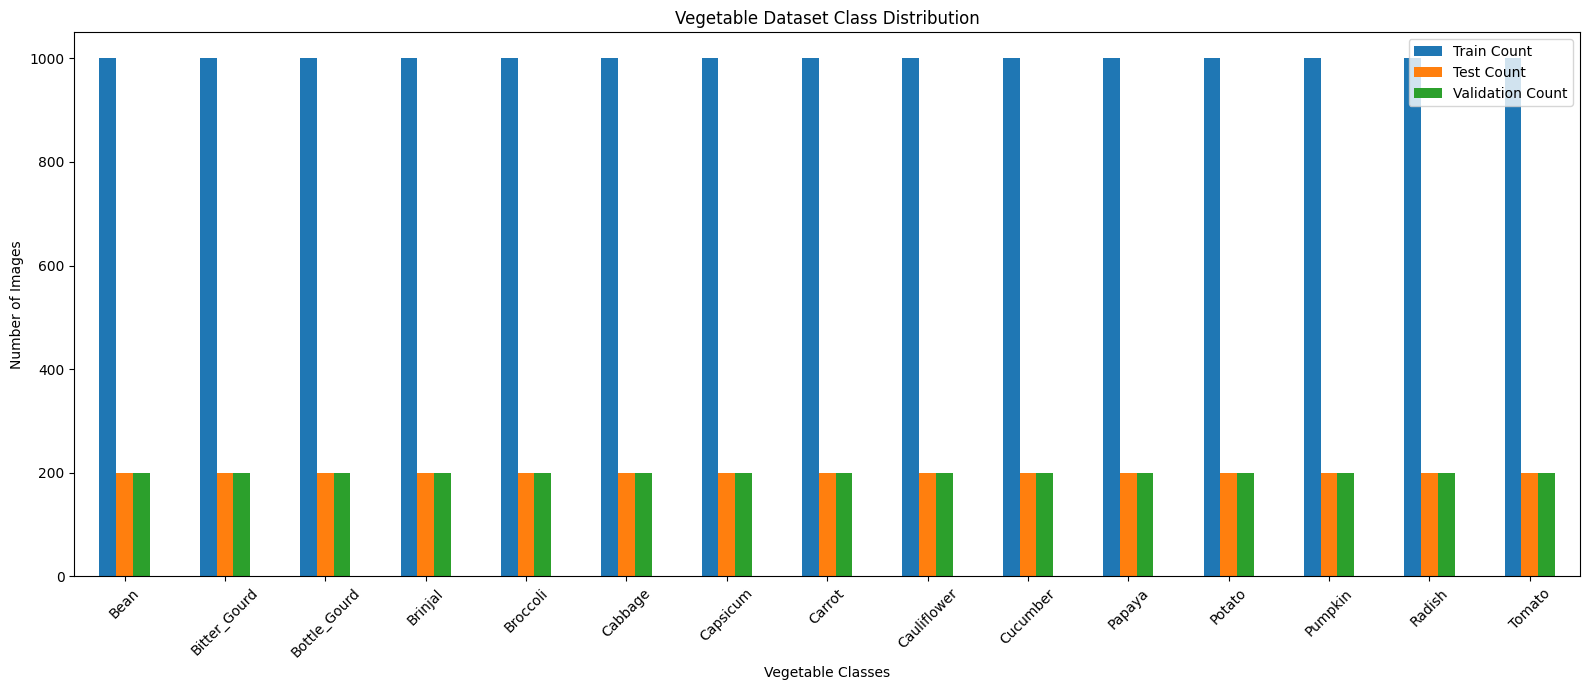

In [52]:
summary_df.plot(x = 'Vegetable',
               y = ["Train Count", "Test Count", "Validation Count"],
               kind = 'bar',
               figsize = (16,7))
plt.title("Vegetable Dataset Class Distribution")
plt.xlabel("Vegetable Classes")

plt.ylabel("Number of Images")

plt.xticks(rotation=45)

plt.legend()

plt.tight_layout()

plt.show()


In [53]:
# "The dataset is relatively balanced because the number of 
#images in each vegetable class is approximately equal."

## Image Preprocessing and Augmentation

In [54]:
train_datagen = ImageDataGenerator(rescale = 1/255,rotation_range = 20,
                        width_shift_range=0.2,height_shift_range=0.2, shear_range=0.2,
                         zoom_range=0.2,horizontal_flip=True,
                         validation_split=0.2)

In [55]:
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

## Load Images Using flow_from_directory

In [56]:
train_ds = train_datagen.flow_from_directory(train_path,target_size = (224,224), batch_size = 32, class_mode = 'categorical', subset = 'training', seed = 42)

Found 12000 images belonging to 15 classes.


In [57]:
val_ds = val_datagen.flow_from_directory(val_path,target_size=(224, 224),
batch_size=32,
class_mode="categorical",
subset="validation",
seed=42
)

Found 600 images belonging to 15 classes.


In [58]:
print("Training Images:", train_ds.samples)

print("Validation Images:", val_ds.samples)

print("Number of Classes:", train_ds.num_classes)

print("Class Names:", train_ds.class_indices)

Training Images: 12000
Validation Images: 600
Number of Classes: 15
Class Names: {'Bean': 0, 'Bitter_Gourd': 1, 'Bottle_Gourd': 2, 'Brinjal': 3, 'Broccoli': 4, 'Cabbage': 5, 'Capsicum': 6, 'Carrot': 7, 'Cauliflower': 8, 'Cucumber': 9, 'Papaya': 10, 'Potato': 11, 'Pumpkin': 12, 'Radish': 13, 'Tomato': 14}


## Build the CNN Model

In [59]:
model = Sequential([

    #conv 1
    Conv2D(32,(3, 3),activation="relu",input_shape=(224, 224, 3)),
    MaxPooling2D((2,2)),

    #conv 2
    Conv2D( 64,(3, 3),activation="relu" ),
    MaxPooling2D((2, 2)),

    # conv 3
    Conv2D(128,(3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(512,activation = 'relu'),

    Dropout(0.5),
    Dense ( 15,activation = 'softmax')
])




In [60]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

In [61]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

##  Train the Model

In [62]:
early_stopping = EarlyStopping(monitor = 'val_loss',patience=5,restore_best_weights=True)

In [ ]:
history = model.fit(train_ds, validation_data = val_ds,epochs = 20,callbacks = [early_stopping])

In [ ]:
train_loss, train_accuracy = model.evaluate(train_ds)

val_loss, val_accuracy = model.evaluate(val_ds)

In [ ]:
print("Training Accuracy:", train_accuracy)
print("Validation Accuracy:", val_accuracy)

print("Training Loss:", train_loss)
print("Validation Loss:", val_loss)

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')

plt.xlabel('Epochs')

plt.ylabel('Accuracy')

plt.legend()

plt.show()

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')

plt.xlabel('Epochs')

plt.ylabel('Loss')

plt.legend()

plt.show()